<a href="https://colab.research.google.com/github/kvikaee/deep-learning/blob/main/%D0%93%D0%9E_%D0%9B%D0%A01_%D0%9A%D0%BE%D1%88%D1%83%D1%80%D0%B8%D0%BD%D0%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

В этой лабораторной работе будут задействованы полносвязные слои. Необходимо решить ряд задач с их помощью.  Набор библиотек: tensorflow, numpy, matplotlib, random

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import random

# seed для воспроизводимости
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


Первая задача - классификация генерированных данных. Для начала сформируйте датасет по следующему принципу: первая группа точек (первый класс) распределена по площади круга радиусом 0.8, вторая группа - по площади кольца с R=2 и r=1. Суммарное количество точек N=1000, соотношение классов - 1:1.

По заданным условиям сгенерируйте две координаты для каждой точки как случайные величины, набор этих координат занесите в массив X_train. Каждой точке из этого массива должен соответствовать лейбл класса - его занесите в y_train. Постройте график распределения.

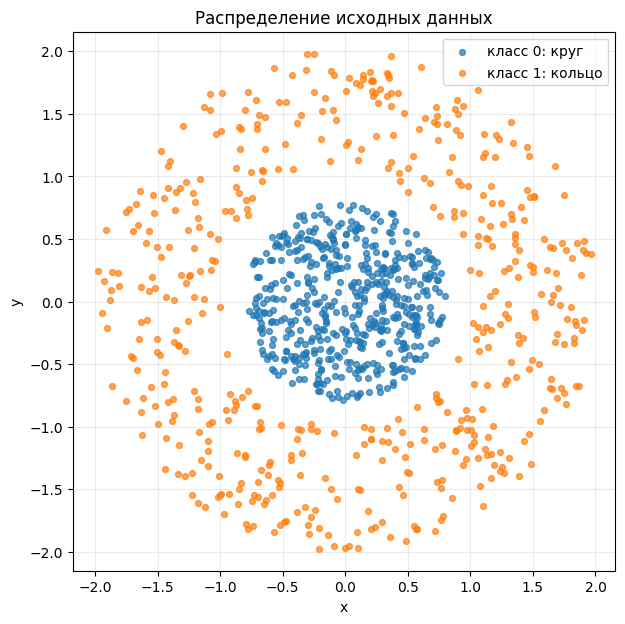

In [ ]:
N = 1000
n_per_class = N // 2

# класс 0: точки равномерно по площади круга радиуса 0.8
theta_circle = np.random.uniform(0, 2 * np.pi, n_per_class)
radius_circle = 0.8 * np.sqrt(np.random.uniform(0, 1, n_per_class))

x_circle = radius_circle * np.cos(theta_circle)
y_circle = radius_circle * np.sin(theta_circle)
class_0 = np.column_stack((x_circle, y_circle))

# класс 1: точки равномерно по площади кольца с r=1 и R=2
theta_ring = np.random.uniform(0, 2 * np.pi, n_per_class)
radius_ring = np.sqrt(np.random.uniform(1**2, 2**2, n_per_class))

x_ring = radius_ring * np.cos(theta_ring)
y_ring = radius_ring * np.sin(theta_ring)
class_1 = np.column_stack((x_ring, y_ring))

X_train = np.vstack((class_0, class_1)).astype(np.float32)
y_train = np.hstack((
    np.zeros(n_per_class, dtype=np.int32),
    np.ones(n_per_class, dtype=np.int32)
))

# перемешиваем данные, чтобы оба класса были представлены в train/validation
indices = np.random.permutation(N)
X_train = X_train[indices]
y_train = y_train[indices]

plt.figure(figsize=(7, 7))
plt.scatter(
    X_train[y_train == 0, 0],
    X_train[y_train == 0, 1],
    s=18,
    alpha=0.7,
    label='класс 0: круг'
)
plt.scatter(
    X_train[y_train == 1, 0],
    X_train[y_train == 1, 1],
    s=18,
    alpha=0.7,
    label='класс 1: кольцо'
)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Распределение исходных данных')
plt.axis('equal')
plt.grid(alpha=0.25)
plt.legend()
plt.show()


Классы "круг" и "кольцо" имеют нелинейную границу разделения, поэтому для их классификации требуется нейронная сеть с несколькими слоями.

Классифицируйте эти данные с помощью трех разных моделей, использующих полносвязные слои. Для всех моделей используйте метрику accuracy. Первая модель должна иметь не более двух слоев (включая выходной) и по два нейрона в каждом слое. Во второй модели добавьте к первому слою ещё один нейрон. Последнюю модель составляйте по своему усмотрению с целью максимально быстро добиться 100% точности.

In [ ]:
# модель 1: два слоя, по два нейрона в каждом
model_1 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(2,)),
    tf.keras.layers.Dense(2, activation='tanh'),
    tf.keras.layers.Dense(2, activation='softmax')
])

model_1.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_1 = model_1.fit(
    X_train,
    y_train,
    epochs=80,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

loss_1, accuracy_1 = model_1.evaluate(X_train, y_train, verbose=0)

print(f'Модель 1: accuracy = {accuracy_1:.4f}')
print(f'Максимальная val_accuracy = {max(history_1.history["val_accuracy"]):.4f}')


Модель 1: accuracy = 0.8380
Максимальная val_accuracy = 0.8200


In [ ]:
# модель 2: в первом слое теперь три нейрона
model_2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(2,)),
    tf.keras.layers.Dense(3, activation='tanh'),
    tf.keras.layers.Dense(2, activation='softmax')
])

model_2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_2 = model_2.fit(
    X_train,
    y_train,
    epochs=80,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

loss_2, accuracy_2 = model_2.evaluate(X_train, y_train, verbose=0)

print(f'Модель 2: accuracy = {accuracy_2:.4f}')
print(f'Максимальная val_accuracy = {max(history_2.history["val_accuracy"]):.4f}')


Модель 2: accuracy = 1.0000
Максимальная val_accuracy = 1.0000


100% train accuracy достигнута на эпохе 3
Модель 3: accuracy = 1.0000
Максимальная val_accuracy = 1.0000


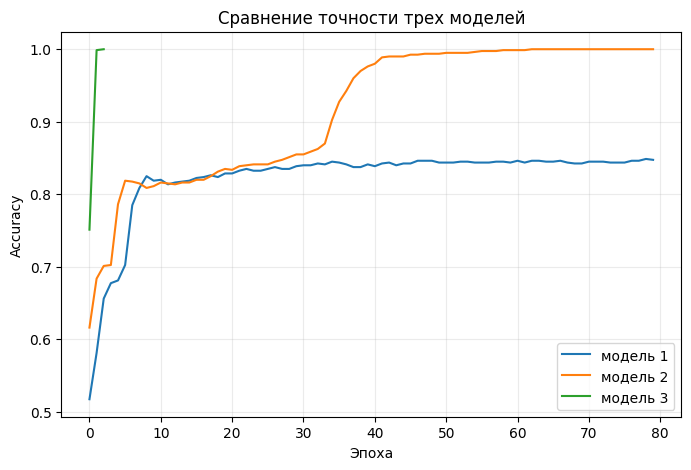

In [ ]:
# третья модель: более глубокая сеть для быстрой аппроксимации круглой границы
def build_model_3():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(2,)),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(2, activation='softmax')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


class StopAtPerfectAccuracy(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        if logs.get('accuracy', 0) >= 1.0:
            print(f'100% train accuracy достигнута на эпохе {epoch + 1}')
            self.model.stop_training = True


model_3 = build_model_3()

history_3 = model_3.fit(
    X_train,
    y_train,
    epochs=150,
    batch_size=32,
    validation_split=0.2,
    callbacks=[StopAtPerfectAccuracy()],
    verbose=0
)

loss_3, accuracy_3 = model_3.evaluate(X_train, y_train, verbose=0)

print(f'Модель 3: accuracy = {accuracy_3:.4f}')
print(f'Максимальная val_accuracy = {max(history_3.history["val_accuracy"]):.4f}')

plt.figure(figsize=(8, 5))
plt.plot(history_1.history['accuracy'], label='модель 1')
plt.plot(history_2.history['accuracy'], label='модель 2')
plt.plot(history_3.history['accuracy'], label='модель 3')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.title('Сравнение точности трех моделей')
plt.grid(alpha=0.25)
plt.legend()
plt.show()


Первая модель достигла точности около 84%, вторая постепенно достигла почти 100%, а третья получила 100% точность уже за несколько эпох. Таким образом, третья модель обучается наиболее быстро.

Теперь добавьте к данным случайные отклонения по координатам таким образом, чтобы точки двух классов смешивались на границе. Для этого, например, можно добавить к генератору координат слагаемое, разыгранное функцией Гаусса, но принимается любой рабочий вариант. Постройте график.

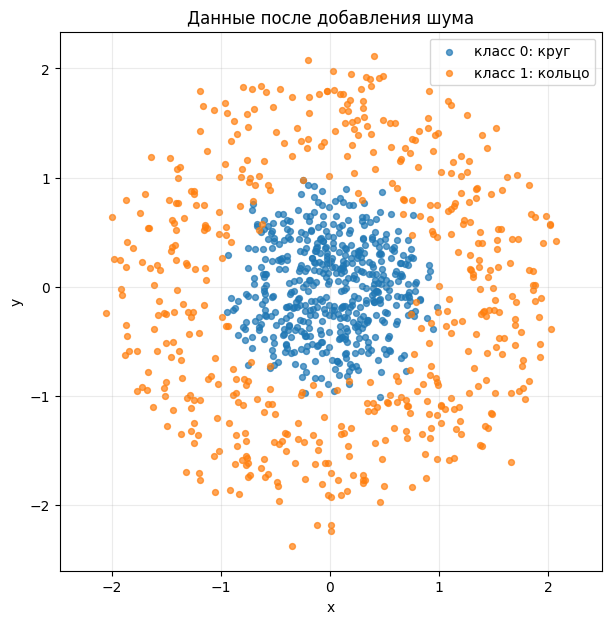

In [ ]:
# добавляем гауссов шум к обеим координатам
noise_std = 0.15
X_train_noisy = X_train + np.random.normal(
    loc=0.0,
    scale=noise_std,
    size=X_train.shape
).astype(np.float32)

plt.figure(figsize=(7, 7))
plt.scatter(
    X_train_noisy[y_train == 0, 0],
    X_train_noisy[y_train == 0, 1],
    s=18,
    alpha=0.7,
    label='класс 0: круг'
)
plt.scatter(
    X_train_noisy[y_train == 1, 0],
    X_train_noisy[y_train == 1, 1],
    s=18,
    alpha=0.7,
    label='класс 1: кольцо'
)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Данные после добавления шума')
plt.axis('equal')
plt.grid(alpha=0.25)
plt.legend()
plt.show()


После добавления шума классы стали сильнее пересекаться, поэтому задача классификации усложнилась.

К этим данным примените третью модель.

Accuracy модели 3 на данных с шумом = 0.9730
Максимальная val_accuracy = 0.9850


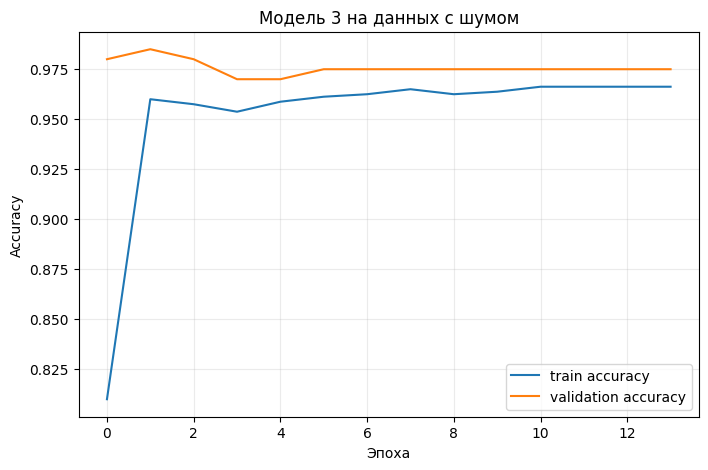

In [ ]:
# используем ту же архитектуру третьей модели, но обучаем ее на данных с шумом
model_3_noisy = build_model_3()

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=12,
    mode='max',
    restore_best_weights=True
)

history_noisy = model_3_noisy.fit(
    X_train_noisy,
    y_train,
    epochs=150,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=0
)

loss_noisy, accuracy_noisy = model_3_noisy.evaluate(
    X_train_noisy,
    y_train,
    verbose=0
)

print(f'Accuracy модели 3 на данных с шумом = {accuracy_noisy:.4f}')
print(f'Максимальная val_accuracy = {max(history_noisy.history["val_accuracy"]):.4f}')

plt.figure(figsize=(8, 5))
plt.plot(history_noisy.history['accuracy'], label='train accuracy')
plt.plot(history_noisy.history['val_accuracy'], label='validation accuracy')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.title('Модель 3 на данных с шумом')
plt.grid(alpha=0.25)
plt.legend()
plt.show()


Несмотря на шум, модель сохранила высокую точность - примерно 96–98% на обучающей и валидационной выборках. Это показывает её устойчивость к искажению данных.

Теперь решите задачу классификации для датасета MNIST. Загрузите его любым удобным способом и обучите FC-модель. Точность выше 90% считается удовлетворительной.

In [ ]:
# загружаем MNIST
(x_train_mnist, y_train_mnist), (x_test_mnist, y_test_mnist) = (
    tf.keras.datasets.mnist.load_data()
)

# переводим значения пикселей из диапазона [0, 255] в [0, 1]
x_train_mnist = x_train_mnist.astype(np.float32) / 255.0
x_test_mnist = x_test_mnist.astype(np.float32) / 255.0

# полносвязная модель
model_mnist = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model_mnist.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_mnist = model_mnist.fit(
    x_train_mnist,
    y_train_mnist,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

test_loss, test_accuracy = model_mnist.evaluate(
    x_test_mnist,
    y_test_mnist,
    verbose=0
)

print(f'Точность на тестовой выборке MNIST = {test_accuracy:.4f}')


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9011 - loss: 0.3449 - val_accuracy: 0.9580 - val_loss: 0.1399
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9560 - loss: 0.1455 - val_accuracy: 0.9703 - val_loss: 0.1045
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9697 - loss: 0.1013 - val_accuracy: 0.9708 - val_loss: 0.0936
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9780 - loss: 0.0757 - val_accuracy: 0.9738 - val_loss: 0.0880
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9832 - loss: 0.0583 - val_accuracy: 0.9738 - val_loss: 0.0854
Точность на тестовой выборке MNIST = 0.9713


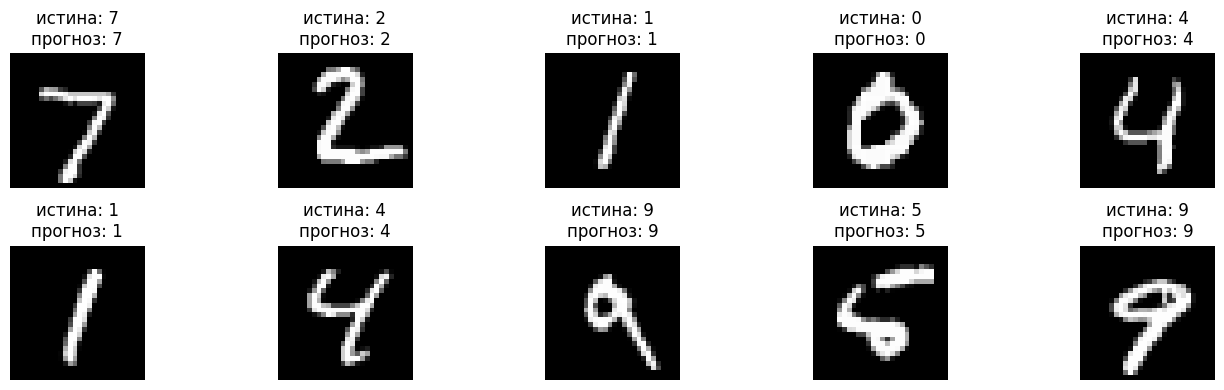

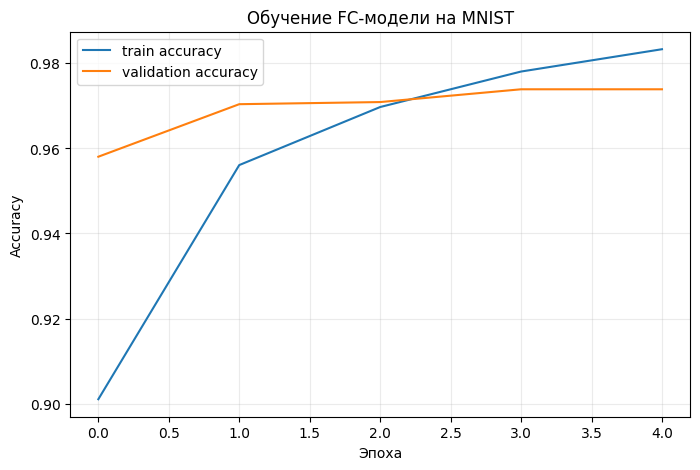

In [ ]:
# посмотрим на несколько предсказаний модели
predictions = model_mnist.predict(x_test_mnist[:10], verbose=0)
predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(14, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test_mnist[i], cmap='gray')
    plt.title(
        f'истина: {y_test_mnist[i]}\n'
        f'прогноз: {predicted_labels[i]}'
    )
    plt.axis('off')

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_mnist.history['accuracy'], label='train accuracy')
plt.plot(history_mnist.history['val_accuracy'], label='validation accuracy')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.title('Обучение FC-модели на MNIST')
plt.grid(alpha=0.25)
plt.legend()
plt.show()



Модель успешно распознаёт рукописные цифры: на представленных примерах все прогнозы совпали с истинными значениями.

### Вывод

В работе были построены полносвязные нейронные сети для двух задач классификации.

- Модель с двумя нейронами в скрытом слое имеет ограниченную способность аппроксимировать круглую границу между классами.
- Добавление третьего нейрона в первый слой повышает качество классификации.
- Более глубокая третья модель лучше описывает нелинейную границу и на исходных, хорошо разделимых данных может достигать 100% accuracy.
- После добавления шума классы частично пересекаются, поэтому качество на валидации снижается: в зоне пересечения по одним координатам нельзя идеально различить все точки.
- Полносвязная модель для MNIST с двумя скрытыми Dense-слоями обеспечивает точность выше требуемых 90%.
